# **AI-Enabled Multiscale Environmental Science Workshop**
## *Geospatial Embeddings for Landscape-Scale Prediction of Surface Water Dynamcis*

### Notebook Overview
This notebook introduces a practical workflow for accessing, visualizing, and analyzing geospatial embeddings, then applies them to similarity search and classification tasks, using the Florida Everglades as our case study.

---

* **Primary Author** Jenna Abrahamson
* **Affiliation:** Pacific Northwest National Laboratory
* **Date:** 6th December, 2026

---

### Objectives

By the end of this notebook, you will be able to:

1. **Learn to access geospatial embeddings** from AlphaEarth, TESSERA, and OlmoEarth for a selected area and year, applying the appropriate dequantization methods.
2. **Visualize and explore spatial patterns** in embeddings using RGB composites and principal component analysis (PCA).
3. **Apply cosine similarity** to identify locations with similar learned features through an interactive map.
4. **Train and evaluate a classification model** using geospatial embeddings

**Bonus Section:** Time permitting, we will compare the embeddings model's performance vs a model trained with Sentinel-2 spectral bands, and generate new predictions using the trained model.

## **Step 1: Set Up Our Environment**

In [1]:
import sys
print(f"Python version: {sys.version}")
print(f"Running on Colab: {'google.colab' in sys.modules}")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Running on Colab: True


In [2]:
# Install notebook dependencies with an fsspec version compatible
# with the gcsfs and datasets packages in this Colab environment.
%pip install -q "fsspec[http]==2025.12.0" s3fs geemap geopandas rasterio folium zarr xarray rioxarray ipyleaflet scikit-learn xgboost contextily

In [38]:
# Import libraries
import os
import gc
import pandas as pd
import geopandas as gpd
import xarray as xr
import zarr
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt
import folium
import matplotlib.cm as cm
import io
import base64
from ipyleaflet import Map, basemaps, ImageOverlay, GeoJSON, Marker
import rioxarray
from rasterio.warp import transform_bounds
import geopandas as gpd
from shapely.geometry import box
from google.colab import drive
import glob
import json

## **Step 2: Fetch Embeddings from Source Cooperative**
#### <u>**Source Cooperative**</u> is a non-profit, data publishing utility built on cloud object storage by Radiant Earth. It lets organizations upload, share, and access large geospatial and environmental datasets using standard HTTP URLs and tools without managing complex servers or proprietary APIs
Check it out here: https://source.coop/

This section will walk through how to fetch data for three different embedding datasets (AlphaEarth, TESSERA, OlmoEarth), only retrieving information for a specific year and area of interest (AOI).

### Set-up Our Year and AOI
Keeping with the theme of rivers and streams, let's look at an example area of interest that focuses on some stream channels off of the Mississippi River.

In [4]:
# Mount Google Drive.
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# Find the AOI anywhere within My Drive.
matches = glob.glob(
    '/content/drive/MyDrive/**/stream_aoi.geojson',
    recursive=True
)

if not matches:
    raise FileNotFoundError("AOI file not found in Google Drive.")
if len(matches) > 1:
    raise ValueError(f"Multiple AOI files found. Use a unique filename: {matches}")

aoi = gpd.read_file(matches[0]).to_crs("EPSG:4326")
print(f"✅ AOI loaded: {len(aoi)} feature(s)")

✅ AOI loaded: 1 feature(s)


In [6]:
# Preserve the CRS declared by the uploaded file.
# If missing, specify the file's actual source CRS below.
AOI_SOURCE_CRS = None  # e.g. "EPSG:2927" only if that is the actual CRS

if aoi.crs is None:
    if AOI_SOURCE_CRS is None:
        raise ValueError(
            "AOI CRS is missing. Set AOI_SOURCE_CRS to the file's actual CRS."
        )
    aoi = aoi.set_crs(AOI_SOURCE_CRS)

aoi = aoi.to_crs("EPSG:4326")
minx, miny, maxx, maxy = aoi.total_bounds
bbox = [minx, miny, maxx, maxy]

print(f"AOI bbox (longitude/latitude): {bbox}")

AOI bbox (longitude/latitude): [np.float64(-91.41849788640613), np.float64(33.933320801094645), np.float64(-91.26208306543373), np.float64(34.03883535904945)]


This next code block sets our year we are going to load embeddings for. You can change this if you want to test loading in different years.

Next, the TESSERA and OlmoEarth datasets use UTM meters, so `utm_bounds` converts the AOI defined above to their coordinate system (AlphaEarth uses lat/long so the bbox defined above is already ready to go).

In [7]:
# Set year of interest
YEAR = 2022

# TESSERA and OlmoEarth use one store group per UTM zone.
utm_zone = min(60, int(((minx + maxx) / 2 + 180) // 6) + 1)
utm_crs = f"EPSG:{32600 + utm_zone}"
utm_bounds = transform_bounds("EPSG:4326", utm_crs, *bbox)

The following sections follow the same five steps. Variable prefixes (aef_, tess_, olmo_) identify each embedding source (AlphaEarth, TESSERA, and OlmoEarth).

### **2.1: Google AlphaEarth Embeddings**

To access AlphaEarth Foundation (AEF) embeddings — a satellite imagery embedding
model developed by Google with 64 dimensions — we'll connect to a copy of this dataset hosted on
[Source Cooperative](https://source.coop/tge-labs/aef-mosaic) (this dataset is also available via Google Earth Engine). This specific
dataset is stored in an Amazon Web Services (AWS) S3 bucket.

> An Amazon S3 (Simple Storage Service) bucket is a cloud-based container
> that stores data objects—such as files, images, backups, and logs—inside
> Amazon Web Services (AWS).

The data itself is stored using Zarr, an open-source format for storing
large, multi-dimensional array datasets (e.g., measurements across time,
space, and other variables) as chunked N-dimensional arrays. Think of it as
a lightweight, modular alternative to older formats like HDF5, designed to
work especially well with cloud storage and distributed computing (Source: https://www.earthmover.io/blog/what-is-zarr/)

**Why this matters for us:** Because Zarr data is chunked and cloud-native,
we can request just the small spatial/temporal slice we need (our area of
interest) without downloading the entire multi-petabyte dataset.


**NOTE:** *The dataset is projected in EPSG:4326 with a fixed pixel size in degrees. This means that pixels cover ~10m on the ground at the equator, but less area at higher latitudes. For area-based analysis, consider reprojecting to an equal-area projection.*

#### Acess the S3 Bucket

In [8]:
# Open the Zarr dataset (this connects to the metadata)
aef_ds = xr.open_zarr(
    's3://us-west-2.opendata.source.coop/tge-labs/aef-mosaic/',
    storage_options={"anon": True},
    consolidated=False,
    chunks=None,
    mask_and_scale=False,
    decode_times=False,
)

print(f"Full shape: {aef_ds['embeddings'].shape}")
print(f"Available years: {aef_ds['time'].values}")

/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3624: ZarrUserWarning: Object at .checkpoint is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/zarr/core/group.py:3624: ZarrUserWarning: Object at README.md is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


Full shape: (9, 64, 1859584, 4009984)
Available years: [2017 2018 2019 2020 2021 2022 2023 2024 2025]


#### Fetching the Data for Our AOI and Selected Year

This pulls **only** the relevant slice from the remote array:

- `time=YEAR` — our selected year (a single value)
- `aef_ds["embeddings"]`— **all** 64 embedding bands/dimensions
- `aef_ymax, aef_ymin` — our AOI's latitude range
- `aef_xmin, aef_xmax` — our AOI's longitude range
- `.load()` - loads the data into memory

**This is the moment actual data transfer happens** — everything before this step was just metadata; no data was pulled from S3 until now.

In [9]:
# Define bbox based on our previoiusly loaded AOI
aef_xmin, aef_ymin, aef_xmax, aef_ymax = bbox

# Load the raw embedding dataset
aef_raw = aef_ds["embeddings"].sel(
    time=YEAR,
    x=slice(aef_xmin, aef_xmax),
    y=slice(aef_ymax, aef_ymin),
).load()

#### Dequantizing: Converting Codes Back to Real Numbers

Before you can analyze this data, you need to convert the stored `int8` codes back
into their original floating-point values. **Don't skip this step** — even though
the codes roughly preserve the order of the original values, using them directly
will give you inaccurate results.

**Why do we need to do this?** To keep file sizes manageable, the original float
values were compressed into `int8` codes (ranging from -127 to 127) using a method
called **"signed square" quantization**. This sacrifices a bit of precision in
exchange for a much smaller dataset — which is what makes a dataset this large
practical to store and share.

**The conversion formula:**

$$\text{float_value} = \text{sign}(x) \times \left(\frac{x}{127.5}\right)^2$$

**Note:** OlmoEarth embeddings use this same method, so this formula applies there too.

**What happens if you skip this step (or get it wrong):**

1. **Distance and similarity calculations break.** Cosine similarity, dot products,
   and other comparisons will give misleading results if run on the raw codes.
2. **Missing data can quietly corrupt your analysis.** Some datasets use a
   placeholder value (e.g., `-128`) to mark missing data. If you don't convert this
   to `NaN` first, it gets treated as a real number — skewing averages, clustering,
   and other calculations with no obvious error or warning.
3. **Math on raw integers can overflow.** Running calculations directly on `int8`
   values (instead of the dequantized floats) can cause numbers to wrap around to
   nonsensical values, again without any warning.

**Takeaway:** Always check the dataset's documentation to see whether it needs
dequantizing before you start your analysis — this is a common gotcha with
embedding datasets.

In [10]:
# Dequantize to float32
aef_q = aef_raw.astype("float32").where(aef_raw != -128)
aef_embeddings = np.sign(aef_q) * (aef_q / 127.5) ** 2

# Convert to a NumPy array ordered as (band, row, column) for analysis
aef_data_float = aef_embeddings.transpose("band", "y", "x").values

#### Inspect the Results

Let's look at the shape of the data, check that the data type is `float32`, and then look at the first ten embedding dimensions for the center pixel in our AOI.

In [11]:
print(f"Shape: {aef_data_float.shape}")
print(f"Data type: {aef_data_float.dtype}")

aef_row, aef_col = np.array(aef_data_float.shape[1:]) // 2
print("Center pixel, first 10 values:", aef_data_float[:10, aef_row, aef_col])

Shape: (64, 1175, 1741)
Data type: float32
Center pixel, first 10 values: [-0.03254133 -0.09842369 -0.16000001  0.03844675 -0.05911573 -0.24415225
  0.16633603  0.10851212 -0.06299116 -0.01574779]


#### Visualize the Data

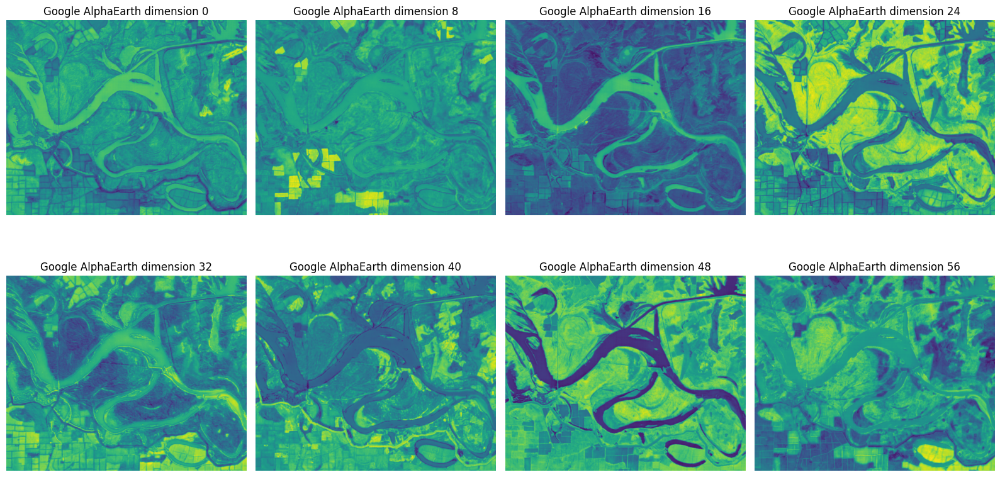

In [12]:
# Plot eight of the AEF dimensions
aef_aspect = 1 / np.cos(np.radians((miny + maxy) / 2)) # Aspect correction
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    band_idx = i * (aef_data_float.shape[0] // 8)
    ax.imshow(aef_data_float[band_idx], cmap="viridis", aspect=aef_aspect)
    ax.set_title(f"Google AlphaEarth dimension {band_idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **2.2: TESSERA Embeddings**
[Tessera](https://source.coop/tessera/tessera) embeddings have 128 dimensions. They exist on Source Cooperative as **one Zarr group per UTM zone**, in native UTM coordinates with no reprojection.

Tessera uses a different quantization from AlphaEarth: int8 values multiplied by a **per-pixel float32 scale** stored in a separate `scales` array. Because of this
we need to make sure we access both the `embeddings` and the `scales` array from Source Coop.

Much of the following code will mirror the above example with AlphaEarth.

In [13]:
# Open the Zarr dataset (this connects to the metadata)
# You'll notice this refererences the UTM zone in the call to S3
tess_ds = xr.open_zarr(
    f's3://us-west-2.opendata.source.coop/tessera/tessera/zarr/v1.1-dclimate/utm{utm_zone:02d}',
    storage_options={"anon": True},
    consolidated=False,
    chunks=None,
    mask_and_scale=False,
    decode_times=False,
)

print(f"Full shape: {tess_ds['embeddings'].shape}")
print(f"Available years: {tess_ds['time'].values}")

Full shape: (9, 128, 1826816, 69632)
Available years: [2017 2018 2019 2020 2021 2022 2023 2024 2025]


In [14]:
# Define bbox based on our previoiusly loaded AOI
tess_xmin, tess_ymin, tess_xmax, tess_ymax = utm_bounds

# Load the raw embedding and scales datasets into memory
tess_raw = tess_ds[["embeddings", "scales"]].sel(
    time=YEAR,
    x=slice(tess_xmin, tess_xmax),
    y=slice(tess_ymax, tess_ymin),
).load()

#### Dequantize Using the `scales` Array
Multiply each pixel's integer codes by its scale. Xarray applies the scale across all 128 dimensions automatically. NaN scales remain NaN in the result.

In [15]:
# Multiplication with the scales array
tess_embeddings = (
    tess_raw["embeddings"].astype("float32")
    * tess_raw["scales"].astype("float32")
)

# Convert to a NumPy array ordered as (band, row, column) for analysis
tess_data_float = tess_embeddings.transpose("band", "y", "x").values

#### Inspect the Results

In [16]:
print(f"Shape: {tess_data_float.shape}")
print(f"Data type: {tess_data_float.dtype}")

tess_row, tess_col = np.array(tess_data_float.shape[1:]) // 2
print("Centre pixel, first 10 values:", tess_data_float[:10, tess_row, tess_col])

Shape: (128, 1193, 1464)
Data type: float32
Centre pixel, first 10 values: [-0.04970472 -0.8449803   2.261565    0.5716043   0.546752    0.79527557
  1.2923228  -1.4165846  -1.1432086   2.1621554 ]


#### Visualize the Data

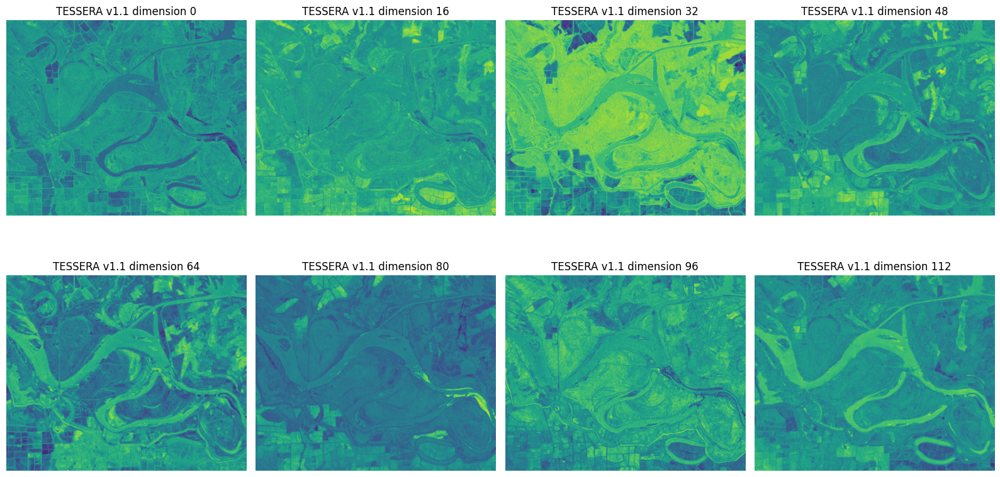

In [17]:
tess_aspect = 1
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    band_idx = i * (tess_data_float.shape[0] // 8)
    ax.imshow(tess_data_float[band_idx], cmap="viridis", aspect=tess_aspect)
    ax.set_title(f"TESSERA v1.1 dimension {band_idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **2.3: OlmoEarth Embeddings**
[OlmoEarth v1.3](https://source.coop/olmoearth/olmoearth-v1-3-embeddings) provides 128 embedding dimensions per pixel. This S3 bucket uses UTM meters.

Again, much of this code will mirror what we have seen with accessing AlphaEarth and TESSERA from Source Cooperative

In [18]:
olmo_ds = xr.open_zarr(
    f's3://olmoearth/olmoearth-v1-3-embeddings/embeddings.zarr/utm{utm_zone:02d}',
    storage_options={
        "anon": True,
        "client_kwargs": {"endpoint_url": "https://data.source.coop"},
    },
    consolidated=False,
    chunks=None,
    mask_and_scale=False,
    decode_times=False,
)

print(f"Full shape: {olmo_ds['embeddings'].shape}")
print(f"Available years: {olmo_ds['time'].values}")

Full shape: (9, 128, 1867776, 98304)
Available years: [2017 2018 2019 2020 2021 2022 2023 2024 2025]


In [19]:
olmo_xmin, olmo_ymin, olmo_xmax, olmo_ymax = utm_bounds

olmo_raw = olmo_ds["embeddings"].sel(
    time=YEAR,
    x=slice(olmo_xmin, olmo_xmax),
    y=slice(olmo_ymax, olmo_ymin),
).load()

#### Dequantize Using the Same Procedure as AEF
Replace the missing-data code (-128) with NaN, then apply the signed-square formula: `sign(q) × (q / 127.5)²`. Cast to `float32` before doing the calculation.

In [20]:
# Dequantize to float32
olmo_q = olmo_raw.astype("float32").where(olmo_raw != -128)
olmo_embeddings = np.sign(olmo_q) * (olmo_q / 127.5) ** 2

# Convert to a NumPy array ordered as (band, row, column) for analysis
olmo_data_float = olmo_embeddings.transpose("band", "y", "x").values

#### Inspect the Results

In [21]:
print(f"Shape: {olmo_data_float.shape}")
print(f"Data type: {olmo_data_float.dtype}")

olmo_row, olmo_col = np.array(olmo_data_float.shape[1:]) // 2
print("Center pixel, first 10 values:", olmo_data_float[:10, olmo_row, olmo_col])

Shape: (128, 1193, 1464)
Data type: float32
Center pixel, first 10 values: [-0.27613997 -0.010396   -0.15378702  0.43404847  0.44444448  0.01574779
  0.02977317  0.2069358   0.292872    0.7994464 ]


#### Visualize the Data

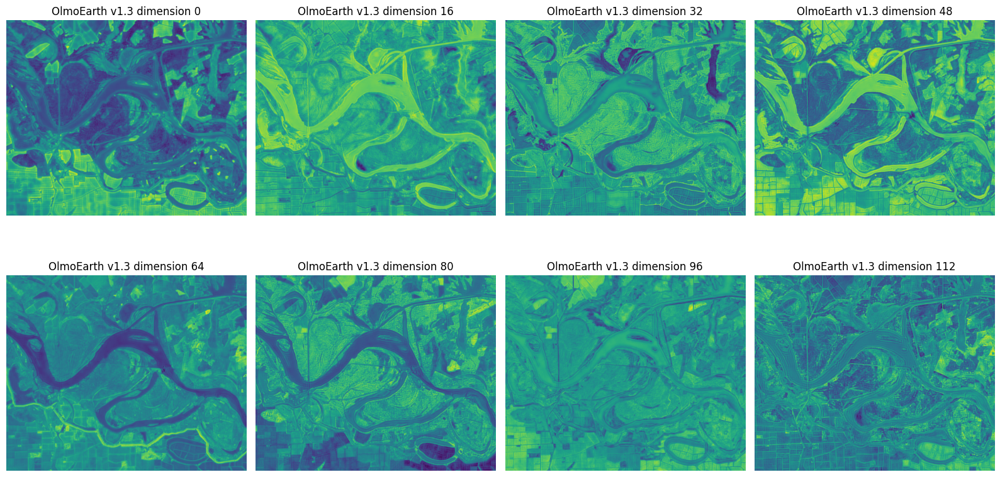

In [22]:
olmo_aspect = 1
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for i, ax in enumerate(axes.flat):
    band_idx = i * (olmo_data_float.shape[0] // 8)
    ax.imshow(olmo_data_float[band_idx], cmap="viridis", aspect=olmo_aspect)
    ax.set_title(f"OlmoEarth v1.3 dimension {band_idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### **2.4: Visual Comparison**

Run the code block below to visualize the first three dimensions of each embedding dataset against one another to compare spatial patterns.

In [23]:
datasets = {
    "AlphaEarth": aef_data_float,
    "TESSERA": tess_data_float,
    "OlmoEarth": olmo_data_float,
}

fig, axes = plt.subplots(3, 3, figsize=(14, 12), constrained_layout=True)

for row, (name, data) in enumerate(datasets.items()):
    # AEF uses degrees; TESSERA and OlmoEarth use UTM metres.
    aspect = aef_aspect if name == "AlphaEarth" else 1

    for dim in range(3):
        ax = axes[row, dim]
        band = data[dim]

        # Scale each panel independently to show its spatial patterns.
        vmin, vmax = np.nanpercentile(band, [2, 98])
        im = ax.imshow(
            band, cmap="viridis", aspect=aspect,
            vmin=vmin, vmax=vmax,
        )
        ax.set_title(f"{name} — dimension {dim}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, shrink=0.7)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

This next code block does the following to visualize patterns in the datasets:
* Fits PCA: combines all embedding dimensions into
three components capturing the most variation in the sampled pixels.
* Creates RGB colors: assigns PC1 to red, PC2 to green, and PC3 to blue.
* Stretches the channels: uses the sample’s 2nd–98th percentiles to make patterns visible.


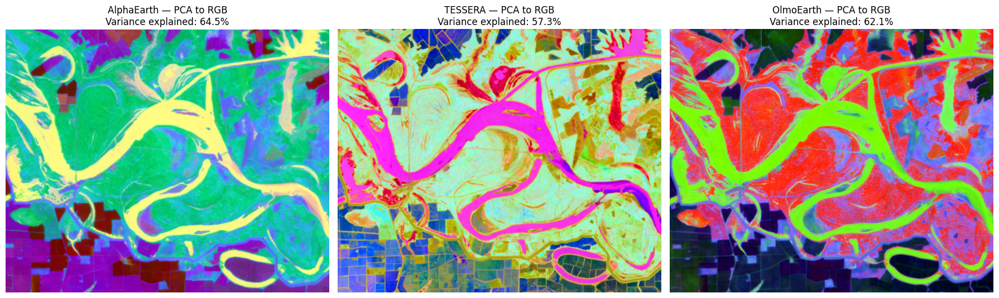

In [24]:
from sklearn.decomposition import PCA

datasets = {
    "AlphaEarth": aef_data_float,
    "TESSERA": tess_data_float,
    "OlmoEarth": olmo_data_float,
}

rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, data) in zip(axes, datasets.items()):
    n_bands, height, width = data.shape
    pixels = data.reshape(n_bands, -1).T  # One embedding vector per pixel
    valid_ids = np.flatnonzero(np.isfinite(data).all(axis=0).ravel())

    # Learn three components from a reproducible sample.
    sample_ids = rng.choice(
        valid_ids, size=min(10_000, len(valid_ids)), replace=False
    )
    pca = PCA(n_components=3, svd_solver="randomized", random_state=42)
    sample_rgb = pca.fit_transform(pixels[sample_ids])

    # Transform all valid pixels in small batches.
    rgb = np.zeros((height * width, 3), dtype="float32")
    low, high = np.percentile(sample_rgb, [2, 98], axis=0)

    for start in range(0, len(valid_ids), 10_000):
        ids = valid_ids[start:start + 10_000]
        colors = pca.transform(pixels[ids])
        rgb[ids] = np.clip(
            (colors - low) / np.maximum(high - low, 1e-8), 0, 1
        )

    aspect = aef_aspect if name == "AlphaEarth" else 1
    ax.imshow(rgb.reshape(height, width, 3), aspect=aspect)
    ax.set_title(
        f"{name} — PCA to RGB\n"
        f"Variance explained: {pca.explained_variance_ratio_.sum():.1%}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## **Step 3: Similarity Search**

### **3.1: Measuring Similarity with Cosine Similarity**

Each pixel is represented by an n-dimensional embedding vector that encodes
features learned by the model. To find locations with similar embeddings,
we compare each pixel's vector with the vector of a selected **query pixel**.

**Cosine similarity** measures how closely two vectors point in the same
direction, regardless of their lengths:

$$
\text{cosine similarity}(\mathbf{a}, \mathbf{b}) =
\begin{array}{c}
\mathbf{a}\cdot\mathbf{b} \\ \hline
\kern0.6em \Vert\mathbf{a}\Vert\,\Vert\mathbf{b}\Vert \kern-0.6em
\end{array}
$$

Here, $\mathbf{a} \cdot \mathbf{b}$ is the dot product, and
$\|\mathbf{a}\|$ and $\|\mathbf{b}\|$ are the vectors' lengths (Euclidean norms).
The score ranges from **−1 to 1**:

- **1:** The vectors point in the same direction.
- **0:** The vectors are perpendicular.
- **−1:** The vectors point in opposite directions.

Higher scores indicate more similar learned features. For example, selecting
a forest pixel may highlight other areas with similar vegetation patterns,
even if they are geographically far apart. Similarity in embedding space
does not guarantee the same land-cover class, and the score is not a probability.

In the demo below, clicking a pixel calculates its cosine similarity to
every pixel in the displayed subset. Green indicates higher similarity
and red indicates lower similarity. The color scale adjusts to the
2nd–98th percentile of scores for each selection, so colors show relative
similarity within that map; red does not necessarily mean a negative score.

### **3.2: Point and Click Similarity Demo**

Run the code block below and then click anywhere on the map below. The map will highlight how similar every
other pixel's embedding is to the pixel you clicked:
- 🟢 Green = highly similar embedding (likely similar land cover/features)
- 🟡 Yellow = moderate similarity
- 🔴 Red = low/negative similarity (very different features)

This demonstrates one of the core use cases for embeddings: finding
similar locations based on learned features, without needing labeled
training data.

#### Run this block
If you're interested in the code used in this section to calculate cosine similarity, feel free to expand this block. For the live workshop we will simply run this block and proceed to the next.

In [33]:
from google.colab import output
output.enable_custom_widget_manager()

# Define helper functions
def latlon_to_rowcol(lat, lon, minx, maxy, pixel_size, n_rows, n_cols):
    """Convert a clicked lat/lon into row/col index within our subset array."""
    col = int((lon - minx) / pixel_size)
    row = int((maxy - lat) / pixel_size)

    # Clamp to valid range
    row = max(0, min(n_rows - 1, row))
    col = max(0, min(n_cols - 1, col))
    return row, col

# This is the function that handles computing the cosine similarity
def compute_similarity_map(row, col, pixel_vectors, pixel_norms, n_rows, n_cols):
    """Compute cosine similarity between the clicked pixel and all other pixels."""
    pixel_idx = row * n_cols + col
    query_vector = pixel_vectors[pixel_idx]
    query_norm = pixel_norms[pixel_idx]

    # Cosine similarity = dot product / (norm_a * norm_b)
    dot_products = pixel_vectors @ query_vector
    similarities = dot_products / (pixel_norms * query_norm + 1e-10)  # avoid div by zero

    return similarities.reshape(n_rows, n_cols)


def similarity_to_png_overlay(similarity_map):
    """Convert similarity array to a base64 PNG for use as a map overlay."""

    vmin = np.percentile(similarity_map, 2)
    vmax = np.percentile(similarity_map, 98)

    # Just print for reference instead of returning
    print(f"Color scale range: {vmin:.3f} to {vmax:.3f}")

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(similarity_map, cmap='RdYlGn', vmin=vmin, vmax=vmax)
    ax.axis('off')

    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0, transparent=True)
    plt.close(fig)
    buf.seek(0)

    encoded = base64.b64encode(buf.read()).decode('utf-8')
    return f"data:image/png;base64,{encoded}"  # ✅ returns ONLY the string

In [34]:
# Use AlphaEarth embeddings for the similarity demo.
similarity_data = aef_data_float

# Reshape (band, row, column) into (pixel, embedding dimension).
n_bands, n_rows, n_cols = similarity_data.shape
pixel_vectors = similarity_data.reshape(n_bands, -1).T

# Precompute vector lengths for cosine similarity.
pixel_norms = np.linalg.norm(pixel_vectors, axis=1)

print(f"Pixel vectors shape: {pixel_vectors.shape}")

Pixel vectors shape: (2045675, 64)


In [35]:
center_lat = (miny + maxy) / 2
center_lon = (minx + maxx) / 2

similarity_map = Map(
    center=(center_lat, center_lon),
    zoom=13,
    basemap=basemaps.Esri.WorldImagery,
    scroll_wheel_zoom=True
)

# Set explicit size - adjust these values to taste
similarity_map.layout.width = '800px'
similarity_map.layout.height = '800px'

# Add AOI boundary
aoi_geojson = GeoJSON(
    data=aoi.__geo_interface__,
    style={'color': 'red', 'fillOpacity': 0, 'weight': 3}
)
similarity_map.add_layer(aoi_geojson)

current_overlay = {'layer': None}
current_marker = {'layer': None}

def handle_click(**kwargs):
    if kwargs.get('type') == 'click':
        lat, lon = kwargs.get('coordinates')

        # Find the AlphaEarth pixel nearest the clicked longitude/latitude.
        col = int(np.abs(aef_embeddings["x"].values - lon).argmin())
        row = int(np.abs(aef_embeddings["y"].values - lat).argmin())
        sim_map = compute_similarity_map(row, col, pixel_vectors, pixel_norms, n_rows, n_cols)

        if current_overlay['layer'] is not None:
            similarity_map.remove_layer(current_overlay['layer'])
        if current_marker['layer'] is not None:
            similarity_map.remove_layer(current_marker['layer'])

        png_data = similarity_to_png_overlay(sim_map)
        overlay = ImageOverlay(
            url=png_data,
            bounds=((miny, minx), (maxy, maxx)),
            opacity=0.7
        )
        similarity_map.add_layer(overlay)
        current_overlay['layer'] = overlay

        marker = Marker(location=(lat, lon))
        similarity_map.add_layer(marker)
        current_marker['layer'] = marker

similarity_map.on_interaction(handle_click)

#### Show the Map

In [36]:
# Show the map
similarity_map

Map(center=[np.float64(33.98607808007205), np.float64(-91.34029047591993)], controls=(ZoomControl(options=['po…

Color scale range: 0.220 to 0.985
Color scale range: 0.231 to 0.981
Color scale range: 0.305 to 0.917
Color scale range: 0.217 to 0.930


#### Run this code block before moving on
This deletes the embedding arrays to free up RAM in the notebook for the next section.

In [37]:
import gc
import matplotlib.pyplot as plt

# Disconnect the interactive map.
if "similarity_map" in globals():
    similarity_map.on_interaction(handle_click, remove=True)
    similarity_map.close()

plt.close("all")

# Release datasets, embedding arrays, and visualization intermediates.
variables_to_clear = [
    "aef_ds", "aef_raw", "aef_q", "aef_embeddings", "aef_data_float",
    "tess_ds", "tess_raw", "tess_embeddings", "tess_data_float",
    "olmo_ds", "olmo_raw", "olmo_q", "olmo_embeddings", "olmo_data_float",
    "datasets", "data", "band", "pixels",
    "similarity_data", "pixel_vectors", "pixel_norms",
    "sample_rgb", "rgb", "colors", "valid_ids", "sample_ids", "pca",
    "similarity_map", "current_overlay", "current_marker",
    "fig", "axes", "ax", "im",
]

for name in variables_to_clear:
    globals().pop(name, None)

gc.collect()
print("✅ Cleared exploration data from memory.")

✅ Cleared exploration data from memory.


## **Step 4: Train a Model to Predict Open Water & Wetland Types**

In this section, we will use embeddings to predict open water and wetland classes in an area of the Florida Everglades using the [National Wetland Inventory](https://www.fws.gov/program/national-wetlands-inventory) dataset to derive training labels. A clipped area of the NWI dataset is stored in the Google Drive folder.

In [39]:
# Grab the NWI dataset programmatically (avoiding space and colon file path issues)
matches = glob.glob('/content/drive/MyDrive/**/everglades_nwi.geojson', recursive=True)
nwi = gpd.read_file(matches[0]).to_crs('EPSG:4326')

### Let's quickly visualize the data we're working with

✅ Loaded 7035 wetland features
CRS: EPSG:4326


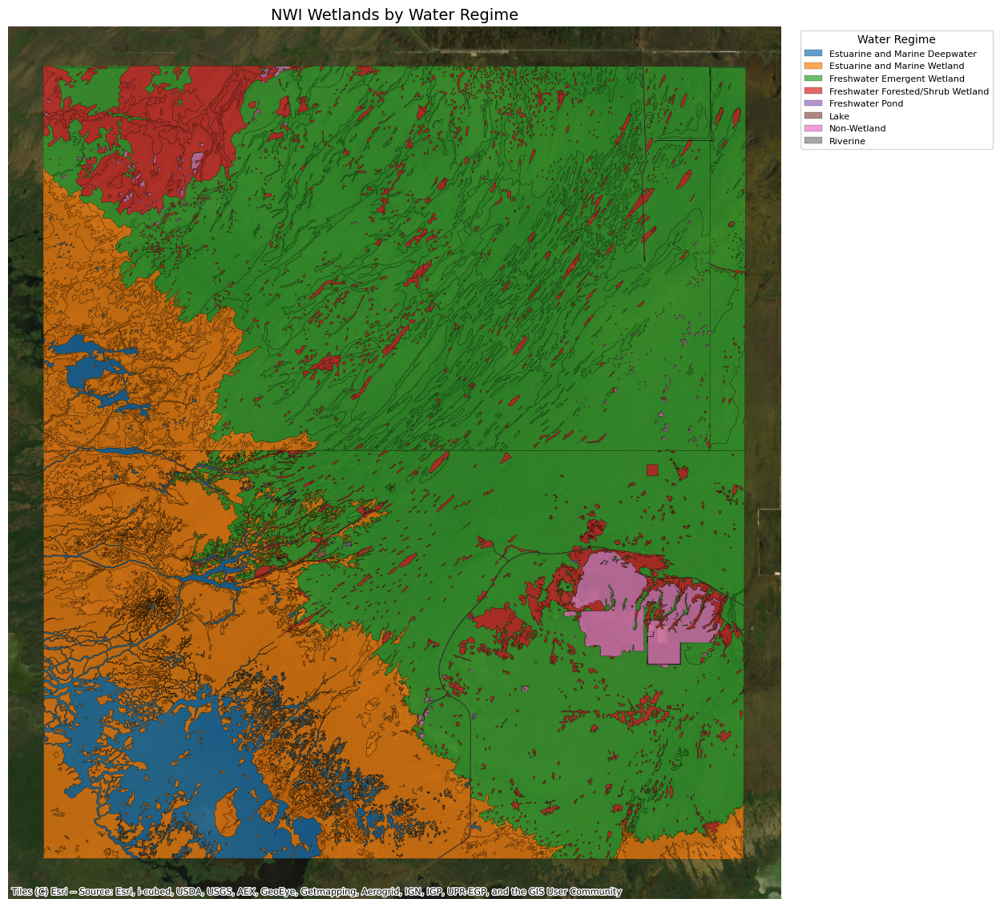

In [41]:
import matplotlib.pyplot as plt
import contextily as cx

# This plots the clipped NWI dataset for context
print(f"✅ Loaded {len(nwi)} wetland features")
print(f"CRS: {nwi.crs}")

# Reproject to Web Mercator (EPSG:3857) - required for contextily basemaps
nwi_web = nwi.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))

# Color by WATER_REGIME, categorical, with legend
nwi_web.plot(
    column='WETLAND_TYPE',
    categorical=True,
    legend=True,
    ax=ax,
    alpha=0.7,              # slightly transparent so basemap shows through
    edgecolor='black',
    linewidth=0.2,
    legend_kwds={
        'loc': 'upper left',
        'bbox_to_anchor': (1.02, 1),  # push legend outside the map
        'title': 'Water Regime',
        'fontsize': 8
    }
)

# Add satellite imagery basemap
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_title('NWI Wetlands by Water Regime', fontsize=14)
ax.set_axis_off()

plt.tight_layout()
plt.show()

### 4.1: Input Prep
Now let's get the data ready for training a lightweight classifier on top of the embeddings. In this section, we consolidate the classes that correspond to open or permanent water in the NWI dataset into a single "Open Water" class.

In [42]:
# Grab the cached embedding files programmatically (avoiding space and path issues)
X_matches = glob.glob('/content/drive/MyDrive/**/olmo_X_valid.npy', recursive=True)
y_matches = glob.glob('/content/drive/MyDrive/**/olmo_y_valid.npy', recursive=True)
class_map_matches = glob.glob('/content/drive/MyDrive/**/class_map.json', recursive=True)

X_valid = np.load(X_matches[0])
y_valid = np.load(y_matches[0])

with open(class_map_matches[0]) as f:
    class_map = json.load(f)
inverse_class_map = {v: k for k, v in class_map.items()}

# Consolidate rare/overlapping WETLAND_TYPE classes into broader categories
consolidation_map = {
    'Non-Wetland': 'Non-Wetland',
    'Freshwater Emergent Wetland': 'Freshwater Emergent Wetland',
    'Freshwater Forested/Shrub Wetland': 'Freshwater Forested/Shrub Wetland',
    'Estuarine and Marine Wetland': 'Estuarine and Marine Wetland',
    'Estuarine and Marine Deepwater': 'Open Water',
    'Freshwater Pond': 'Open Water',
    'Lake': 'Open Water',
    'Riverine': 'Open Water',
}

# Build lookup array using the ORIGINAL class_map (before overwriting)
consolidated_names = sorted(set(consolidation_map.values()))
lookup = np.zeros(len(class_map), dtype=np.uint8)
for original_name, original_int in class_map.items():
    lookup[original_int] = consolidated_names.index(consolidation_map[original_name])

# Overwrite y_valid in place with consolidated labels
y_valid = lookup[y_valid]

# Overwrite class_map / inverse_class_map to reflect the new consolidated classes
class_map = {name: i for i, name in enumerate(consolidated_names)}
inverse_class_map = {v: k for k, v in class_map.items()}

print(f"Consolidated class map: {class_map}")
print("Consolidated class distribution:")
print(pd.Series(y_valid).map(inverse_class_map).value_counts())

Consolidated class map: {'Estuarine and Marine Wetland': 0, 'Freshwater Emergent Wetland': 1, 'Freshwater Forested/Shrub Wetland': 2, 'Non-Wetland': 3, 'Open Water': 4}
Consolidated class distribution:
Freshwater Emergent Wetland          46617
Estuarine and Marine Wetland         15322
Freshwater Forested/Shrub Wetland     5122
Open Water                            3784
Non-Wetland                           1155
Name: count, dtype: int64


### 4.2: Split the data into training and testing

In [43]:
from sklearn.model_selection import train_test_split

# Split data into training and testing using a 70/30 split
X_train, X_test, y_train, y_test = train_test_split(
    X_valid, y_valid, test_size=0.3, random_state=42, stratify=y_valid
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")

Training samples: 50400
Test samples: 21600


### 4.3: Train a Random Forest Model

In [44]:
from sklearn.ensemble import RandomForestClassifier
import time

start = time.time()

# Train a random forest model
clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    n_jobs=-1,
    random_state=42,
    class_weight='balanced'  # helps with class imbalance
)
clf.fit(X_train, y_train)

print(f"✅ Trained in {time.time() - start:.1f} seconds")

✅ Trained in 26.1 seconds


### 4.4: Evaluate Accuracy

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict on the test set
y_pred = clf.predict(X_test)

# Print the overall accuracy
overall_acc = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {overall_acc:.4f}\n")

# Print the classification report
target_names = [inverse_class_map[c] for c in sorted(set(y_test) | set(y_pred))]
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

Overall Accuracy: 0.9041

                                   precision    recall  f1-score   support

     Estuarine and Marine Wetland       0.90      0.92      0.91      4597
      Freshwater Emergent Wetland       0.98      0.91      0.94     13985
Freshwater Forested/Shrub Wetland       0.56      0.83      0.67      1537
                      Non-Wetland       0.70      0.78      0.74       346
                       Open Water       0.87      0.94      0.90      1135

                         accuracy                           0.90     21600
                        macro avg       0.80      0.88      0.83     21600
                     weighted avg       0.92      0.90      0.91     21600



### 4.5: Investigate Feature Importance

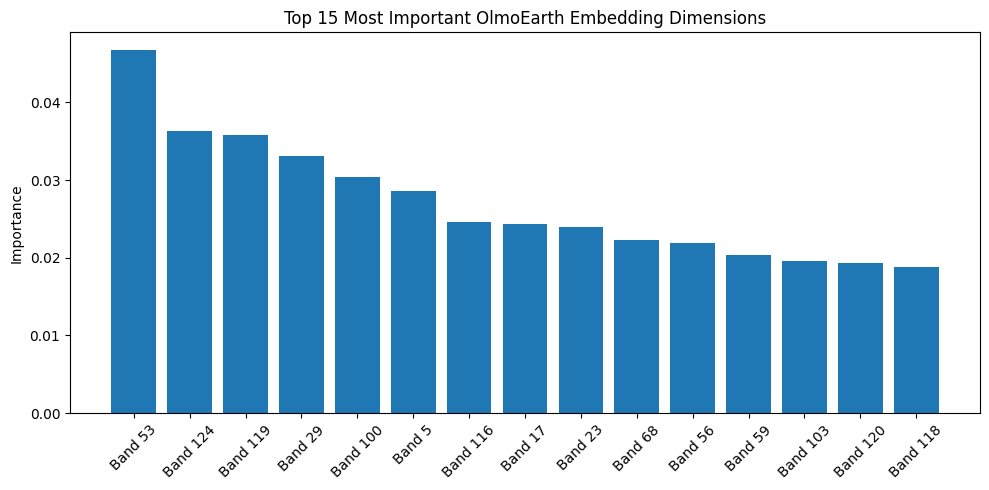

In [15]:
# Make a bar chart of the top 15 embedding dimesions
importances = clf.feature_importances_
top_n = 15
top_idx = np.argsort(importances)[-top_n:][::-1]

plt.figure(figsize=(10, 5))
plt.bar(range(top_n), importances[top_idx])
plt.xticks(range(top_n), [f'Band {i}' for i in top_idx], rotation=45)
plt.title(f'Top {top_n} Most Important OlmoEarth Embedding Dimensions')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

### *Interpreting Feature Importance*

This graph highlights a key challenge of working with geospatial embeddings: **predictive importance does not necessarily translate into physical meaning**. The model may rely more heavily on dimension 53 than dimension 118, but the graph alone does not explain which environmental characteristics those dimensions represent.

Embedding dimensions are learned features, and meaningful patterns may be distributed across multiple dimensions. Exploring their relationships with known environmental variables can provide insight, but individual dimensions may not have a clear physical interpretation.

**The level of interpretability your analysis requires should inform whether—and how—you use geospatial embeddings.**

# **Bonus Sections**
Time permitting, we will run these next sections. But feel free to explore these on your own time as well if we don't get to them!

### **Bonus 1:** Pitt Embeddings against Sentinel-2

To avoid live network fetches and memory crashes during the workshop, we
pre-extracted and cached this dataset ahead of time using a standalone local
script (not run live, but available in the Google Drive folder). For each sampled pixel, both the OlmoEarth embedding *and*
the matching Sentinel-2 band values (from the least-cloudy scene covering the
AOI that year, mosaicked from multiple tiles where needed) were saved together.
Using the *same* random sample indices for both feature sets ensures the
comparison is a true apples-to-apples test — both classifiers are trained and
evaluated on identical pixels, just with different feature representations.

In [45]:
# Grab the comparison dataset files we created offline
X_embed_matches = glob.glob('/content/drive/MyDrive/**/compare_X_embed.npy', recursive=True)
X_s2_matches = glob.glob('/content/drive/MyDrive/**/compare_X_s2.npy', recursive=True)
y_matches = glob.glob('/content/drive/MyDrive/**/compare_y.npy', recursive=True)
class_map_matches = glob.glob('/content/drive/MyDrive/**/compare_class_map.json', recursive=True)
s2_bands_matches = glob.glob('/content/drive/MyDrive/**/compare_s2_bands.json', recursive=True)

X_embed = np.load(X_embed_matches[0])
X_s2 = np.load(X_s2_matches[0])
y = np.load(y_matches[0])

with open(class_map_matches[0]) as f:
    class_map = json.load(f)
inverse_class_map = {v: k for k, v in class_map.items()}

with open(s2_bands_matches[0]) as f:
    s2_bands = json.load(f)

print(f"✅ Loaded comparison dataset")
print(f"Embeddings shape: {X_embed.shape}")
print(f"Sentinel-2 shape: {X_s2.shape} (bands: {s2_bands})")
print(f"Labels shape: {y.shape}")
print(f"Classes: {class_map}")

✅ Loaded comparison dataset
Embeddings shape: (36000, 128)
Sentinel-2 shape: (36000, 6) (bands: ['B02', 'B03', 'B04', 'B08', 'B11', 'B12'])
Labels shape: (36000,)
Classes: {'Estuarine and Marine Deepwater': 0, 'Estuarine and Marine Wetland': 1, 'Freshwater Emergent Wetland': 2, 'Freshwater Forested/Shrub Wetland': 3, 'Freshwater Pond': 4, 'Lake': 5, 'Non-Wetland': 6, 'Riverine': 7}


This is the same class consolidation and data prep that we did before:

In [46]:
# Consolidate rare/overlapping classes into broader categories
consolidation_map = {
    'Non-Wetland': 'Non-Wetland',
    'Freshwater Emergent Wetland': 'Freshwater Emergent Wetland',
    'Freshwater Forested/Shrub Wetland': 'Freshwater Forested/Shrub Wetland',
    'Estuarine and Marine Wetland': 'Estuarine and Marine Wetland',
    'Estuarine and Marine Deepwater': 'Open Water',
    'Freshwater Pond': 'Open Water',
    'Lake': 'Open Water',
    'Riverine': 'Open Water',
}

# Build lookup array using the ORIGINAL class_map (before overwriting)
consolidated_names = sorted(set(consolidation_map.values()))
lookup = np.zeros(len(class_map), dtype=np.uint8)
for original_name, original_int in class_map.items():
    lookup[original_int] = consolidated_names.index(consolidation_map[original_name])

# Overwrite y in place with consolidated labels
y = lookup[y]

# Overwrite class_map / inverse_class_map to reflect the new consolidated classes
class_map = {name: i for i, name in enumerate(consolidated_names)}
inverse_class_map = {v: k for k, v in class_map.items()}

print(f"Consolidated class map: {class_map}")
print("Consolidated class distribution:")
print(pd.Series(y).map(inverse_class_map).value_counts())

Consolidated class map: {'Estuarine and Marine Wetland': 0, 'Freshwater Emergent Wetland': 1, 'Freshwater Forested/Shrub Wetland': 2, 'Non-Wetland': 3, 'Open Water': 4}
Consolidated class distribution:
Estuarine and Marine Wetland         14532
Freshwater Emergent Wetland          13988
Open Water                            4085
Freshwater Forested/Shrub Wetland     3303
Non-Wetland                             92
Name: count, dtype: int64


Again, split training and testing data ensuring the same points are used for both the embedding model and the Sentinel-2 model.

In [15]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices, test_size=0.3, random_state=42, stratify=y
)

X_embed_train, X_embed_test = X_embed[train_idx], X_embed[test_idx]
X_s2_train, X_s2_test = X_s2[train_idx], X_s2[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Training samples: {len(train_idx)}")
print(f"Test samples: {len(test_idx)}")

Training samples: 25200
Test samples: 10800


Train two separate Random Forest models.

In [16]:
from sklearn.ensemble import RandomForestClassifier
import time

start = time.time()
clf_embed = RandomForestClassifier(
    n_estimators=100, max_depth=10, n_jobs=-1, random_state=42, class_weight='balanced'
)
clf_embed.fit(X_embed_train, y_train)
print(f"✅ Embeddings model trained in {time.time() - start:.1f}s")

start = time.time()
clf_s2 = RandomForestClassifier(
    n_estimators=100, max_depth=10, n_jobs=-1, random_state=42, class_weight='balanced'
)
clf_s2.fit(X_s2_train, y_train)
print(f"✅ Sentinel-2 model trained in {time.time() - start:.1f}s")

✅ Embeddings model trained in 19.3s
✅ Sentinel-2 model trained in 3.8s


Compare accuracy metrics against one another.

In [17]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_embed = clf_embed.predict(X_embed_test)
y_pred_s2 = clf_s2.predict(X_s2_test)

acc_embed = accuracy_score(y_test, y_pred_embed)
acc_s2 = accuracy_score(y_test, y_pred_s2)

print(f"{'Model':<20} {'Overall Accuracy':>18}")
print(f"{'-'*40}")
print(f"{'OlmoEarth Embeddings':<20} {acc_embed:>18.4f}")
print(f"{'Raw Sentinel-2 Bands':<20} {acc_s2:>18.4f}")

target_names = [inverse_class_map[c] for c in sorted(set(y_test))]

print("\n" + "="*60)
print("EMBEDDINGS - Classification Report")
print("="*60)
print(classification_report(y_test, y_pred_embed, target_names=target_names, zero_division=0))

print("\n" + "="*60)
print("RAW SENTINEL-2 - Classification Report")
print("="*60)
print(classification_report(y_test, y_pred_s2, target_names=target_names, zero_division=0))

Model                  Overall Accuracy
----------------------------------------
OlmoEarth Embeddings             0.8917
Raw Sentinel-2 Bands             0.7661

EMBEDDINGS - Classification Report
                                   precision    recall  f1-score   support

     Estuarine and Marine Wetland       0.93      0.89      0.91      4360
      Freshwater Emergent Wetland       0.94      0.88      0.91      4196
Freshwater Forested/Shrub Wetland       0.70      0.88      0.78       991
                      Non-Wetland       0.32      0.21      0.26        28
                       Open Water       0.82      0.93      0.88      1225

                         accuracy                           0.89     10800
                        macro avg       0.74      0.76      0.75     10800
                     weighted avg       0.90      0.89      0.89     10800


RAW SENTINEL-2 - Classification Report
                                   precision    recall  f1-score   support

     Estu

Visualize Per-Class F-1 Scores

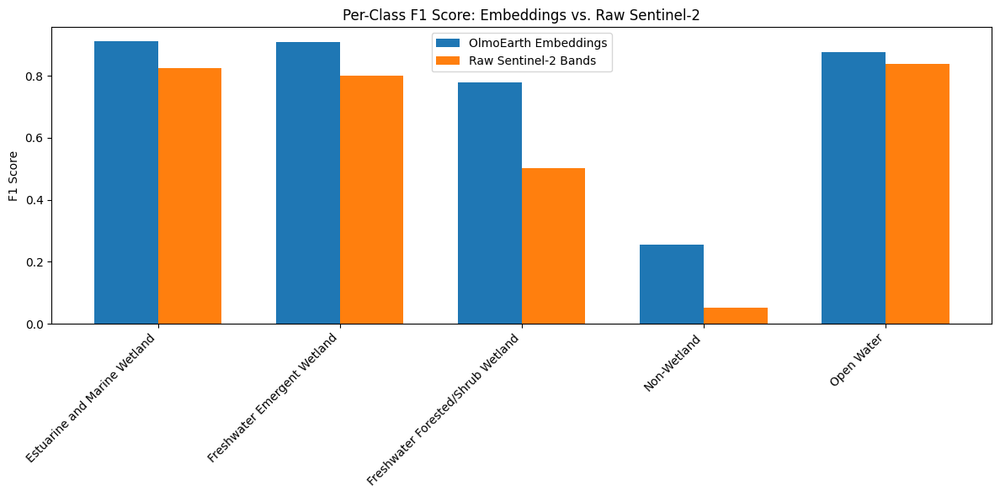

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

f1_embed = f1_score(y_test, y_pred_embed, average=None, labels=sorted(set(y_test)), zero_division=0)
f1_s2 = f1_score(y_test, y_pred_s2, average=None, labels=sorted(set(y_test)), zero_division=0)

x = np.arange(len(target_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width/2, f1_embed, width, label='OlmoEarth Embeddings')
ax.bar(x + width/2, f1_s2, width, label='Raw Sentinel-2 Bands')

ax.set_ylabel('F1 Score')
ax.set_title('Per-Class F1 Score: Embeddings vs. Raw Sentinel-2')
ax.set_xticks(x)
ax.set_xticklabels(target_names, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

### **Bonus 2:** Predict on a New Year of Data with Embeddings

In this section, we will take the model that we trained using OlmoEarth embeddings from 2020 and predict on 2024 OlmoEarth embeddings. This section is to show how you would go about running prediction once you have your trained model.

In [47]:
# Reload the NWI AOI (same glob pattern as your original geojson loading)
nwi_matches = glob.glob('/content/drive/MyDrive/**/everglades_nwi.geojson', recursive=True)
nwi = gpd.read_file(nwi_matches[0]).to_crs('EPSG:4326')

minx, miny, maxx, maxy = nwi.total_bounds
center_lon = (minx + maxx) / 2
center_lat = (miny + maxy) / 2

utm_zone = int((center_lon + 180) / 6) + 1
utm_epsg = f"EPSG:{32600 + utm_zone}" if center_lat >= 0 else f"EPSG:{32700 + utm_zone}"

nwi_utm = nwi.to_crs(utm_epsg)
utm_xmin, utm_ymin, utm_xmax, utm_ymax = nwi_utm.total_bounds

print(f"UTM zone: {utm_zone}, EPSG: {utm_epsg}")
print(f"UTM bounds: {utm_xmin}, {utm_ymin}, {utm_xmax}, {utm_ymax}")

UTM zone: 17, EPSG: EPSG:32617
UTM bounds: 489170.123000031, 2790768.4194834987, 540231.4374998806, 2848179.9989848724


In [48]:
# You should already have these from earlier in the notebook:
# clf_embed (trained RandomForestClassifier)
# class_map, inverse_class_map
# utm_zone, utm_epsg (or recompute from your AOI if needed)

NEW_YEAR = 2024  # the year you want to predict on
TILE_SIZE_M = 10000  # match whatever worked for your extraction

def get_tile_bounds(xmin, ymin, xmax, ymax, tile_size_m):
    tiles = []
    x = xmin
    while x < xmax:
        y = ymin
        while y < ymax:
            tiles.append((x, y, min(x + tile_size_m, xmax), min(y + tile_size_m, ymax)))
            y += tile_size_m
        x += tile_size_m
    return tiles

tiles = get_tile_bounds(utm_xmin, utm_ymin, utm_xmax, utm_ymax, TILE_SIZE_M)
print(f"Processing {len(tiles)} tiles for prediction")

Processing 36 tiles for prediction


In [49]:
# Set up our output map
pixel_size = 10  # OlmoEarth's native resolution in meters - adjust if different
full_width = int((utm_xmax - utm_xmin) / pixel_size)
full_height = int((utm_ymax - utm_ymin) / pixel_size)

label_map = np.full((full_height, full_width), 255, dtype=np.uint8)  # 255 = nodata
print(f"Output map shape: {label_map.shape}")

# Set to True only after completing predictions in this session.
predictions_generated = False

Output map shape: (5741, 5106)


This is where we load new embeddings data and predict.

**NOTE:** this next cell will take quite a few minutes to run. I highly recommend skipping this and go below where we load in the output that I saved to Google Drive earlier after running this cell.

In [50]:
# Access OlmoEarth embeddings on Source Coop
olmo_ds = xr.open_zarr(
    f's3://olmoearth/olmoearth-v1-3-embeddings/embeddings.zarr/utm{utm_zone:02d}',
    storage_options={
        "anon": True,
        "client_kwargs": {"endpoint_url": "https://data.source.coop"},
    },
    consolidated=False,
    chunks="auto",
    mask_and_scale=False,
    decode_times=False,
)

# Iterate through sub-tiles
# This is so we don't load the whole AOI of embeddings into memory but pull and
# predict in smaller chunks
for i, (txmin, tymin, txmax, tymax) in enumerate(tiles):
    try:
        tile_raw = olmo_ds["embeddings"].sel(
            time=NEW_YEAR, x=slice(txmin, txmax), y=slice(tymax, tymin)
        ).load()

        if tile_raw.size == 0:
            print(f"Tile {i}: empty, skipping")
            continue

        tile_q = tile_raw.astype("float32").where(tile_raw != -128)
        tile_embeddings = np.sign(tile_q) * (tile_q / 127.5) ** 2
        tile_data = tile_embeddings.transpose("band", "y", "x").values

        n_bands, n_rows, n_cols = tile_data.shape
        if n_rows == 0 or n_cols == 0:
            continue

        X_tile = tile_data.reshape(n_bands, -1).T
        valid = ~np.isnan(X_tile).any(axis=1)

        preds = np.full(X_tile.shape[0], 255, dtype=np.uint8)
        if valid.sum() > 0:
            preds[valid] = clf_embed.predict(X_tile[valid]).astype(np.uint8)

        tile_label_map = preds.reshape(n_rows, n_cols)

        # Figure out where this tile goes in the full output array
        row_off = int((utm_ymax - tymax) / pixel_size)
        col_off = int((txmin - utm_xmin) / pixel_size)
        label_map[row_off:row_off + n_rows, col_off:col_off + n_cols] = tile_label_map

        del tile_raw, tile_q, tile_embeddings, tile_data, X_tile, preds, tile_label_map
        gc.collect()

        print(f"Tile {i+1}/{len(tiles)} predicted")

    except Exception as e:
        print(f"⚠️ Tile {i} failed: {e}")
        continue

# Set predictions generated to True
predictions_generated = True
print(f"✅ Full prediction map complete: {label_map.shape}")

KeyboardInterrupt: 

#### Plot the final prediction map!

Loaded: /content/drive/MyDrive/AGU Workshop: AI-Enabled Multiscale Environmental Science/Part 2, Module 3: Geospatial Foundation Models for Landscape-Scale Prediction/data/prediction_2024.tif


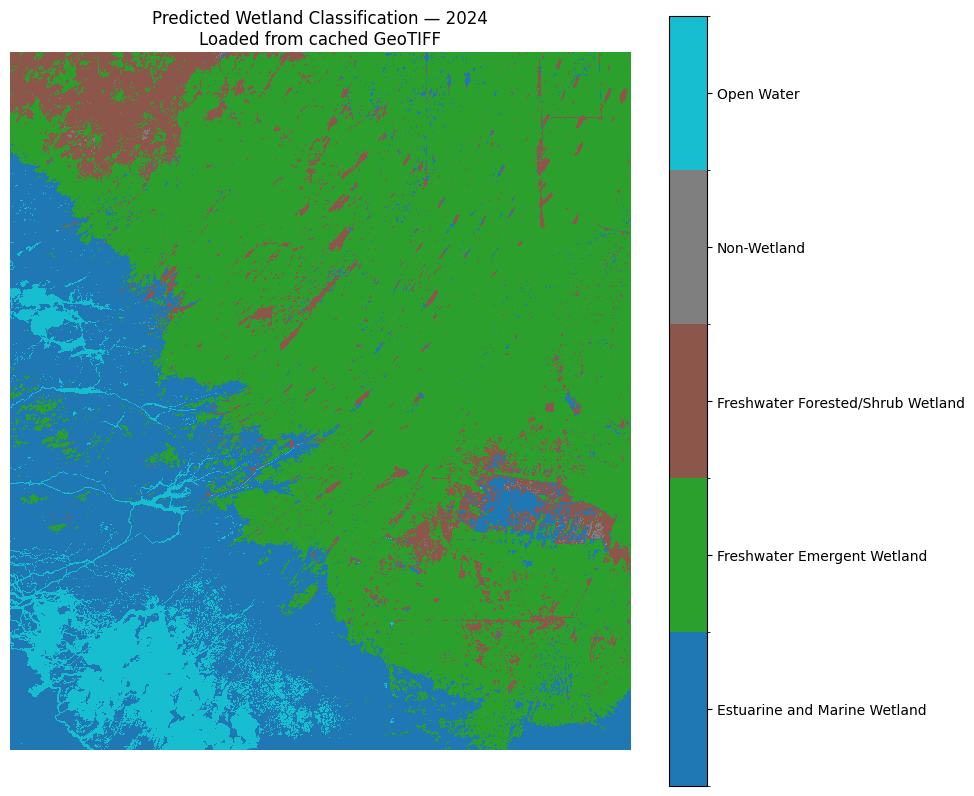

In [53]:
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

if predictions_generated:
    # Plot predictions generated in this session.
    plot_data = np.ma.masked_equal(label_map, 255)
    source_label = "Generated in this session"

else:
    # Find the previously generated GeoTIFF in Google Drive.
    filename = f"prediction_{NEW_YEAR}.tif"
    matches = glob.glob(
        f"/content/drive/MyDrive/**/{filename}",
        recursive=True,
    )

    if not matches:
        raise FileNotFoundError(f"{filename} not found in Google Drive.")
    if len(matches) > 1:
        raise ValueError(f"Multiple matching files found: {matches}")

    with rasterio.open(matches[0]) as src:
        plot_data = src.read(1, masked=True)

    source_label = "Loaded from cached GeoTIFF"
    print(f"Loaded: {matches[0]}")

# Use discrete colors for the numeric class labels.
n_classes = len(class_map)
cmap = plt.get_cmap("tab10", n_classes)
norm = BoundaryNorm(np.arange(n_classes + 1) - 0.5, n_classes)

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(
    plot_data,
    cmap=cmap,
    norm=norm,
    interpolation="nearest",
)

cbar = fig.colorbar(im, ax=ax, ticks=range(n_classes))
cbar.ax.set_yticklabels(
    [inverse_class_map[i] for i in range(n_classes)]
)

ax.set_title(
    f"Predicted Wetland Classification — {NEW_YEAR}\n{source_label}"
)
ax.axis("off")
plt.show()